# ICC check: reproducibility of features


For every feature, the values of the **baseline** (the CSV) and of the **perturbed extractions**
(`reproducibility_analysis.ipynb`: ROI -10 %, ROI +10 %, N4 bias correction, added noise) form a table of
n subjects (breasts) x k conditions ("raters"). From its two-way ANOVA, the intraclass correlation coefficient is
computed following **Shrout & Fleiss (1979)**:

| form | model | formula |
|---|---|---|
| ICC(1,1) | one-way random | (BMS - WMS) / (BMS + (k-1) WMS) |
| ICC(2,1) | two-way random, absolute agreement | (BMS - EMS) / (BMS + (k-1) EMS + k (JMS - EMS) / n) |
| ICC(3,1) | two-way mixed, consistency | (BMS - EMS) / (BMS + (k-1) EMS) |
| ICC(1,k), ICC(2,k), ICC(3,k) | same, for the mean of the k conditions | |

BMS = between subjects, WMS = within subjects, JMS = between conditions, EMS = residual mean square.

**ICC(2,1)** is used for reproducibility: the perturbations are a random sample of possible changes, and the
feature value itself (absolute agreement) must stay the same. It is computed separately for each MRI channel;
a feature is called reproducible if ICC(2,1) >= `THRESHOLD` in every channel.

Categories: < 0.5 poor, 0.5-0.75 moderate, 0.75-0.9 good, > 0.9 excellent.

In [1]:
import sys
from pathlib import Path

# folders of the pipeline code, so that its modules can be imported from this notebook
CODE_ROOT = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline")
for folder in ["", "scripts", "pre_processing", "feature_extraction", "post_processing"]:
    if str(CODE_ROOT / folder) not in sys.path:
        sys.path.insert(0, str(CODE_ROOT / folder))

from pathlib import Path
from IPython.display import display
from icc import run_icc_analysis, shrout_fleiss_example

FEATURE_DIR = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/features/pyradiomics")
CSV_PATH = FEATURE_DIR / "features_raw_image.csv"       # <- feature CSV to check
REPRO_DIR = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/reproducibility")   # perturbed extractions
OUTPUT_DIR = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/icc")

import yaml
config_path = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/config_files/setup.yaml")

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

config

THRESHOLD = config["THRESHOLD_REPRODUCIBILITY"]      # reproducible if ICC(2,1) >= THRESHOLD in every MRI channel

## Perturbed extractions

Extracts every task again under the four perturbations (ROI -10 %, ROI +10 %, N4, noise), with the same settings and
filters as the feature CSVs (Gabor and Laws included). The first run makes 160 extractions.


In [2]:
from reproducibility import run_perturbations

status = run_perturbations(workers=3)      # writes REPRO_DIR/<perturbation>/<task>.json


Fixed bin Count enabled! However, we recommend using a fixed bin Width. See http://pyradiomics.readthedocs.io/en/latest/faq.html#radiomics-fixed-bin-width for more details
Fixed bin Count enabled! However, we recommend using a fixed bin Width. See http://pyradiomics.readthedocs.io/en/latest/faq.html#radiomics-fixed-bin-width for more details
Fixed bin Count enabled! However, we recommend using a fixed bin Width. See http://pyradiomics.readthedocs.io/en/latest/faq.html#radiomics-fixed-bin-width for more details
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmet

  1/160 volume_minus10  BreastMRI002_L_ch0     ok     39.9


Fixed bin Count enabled! However, we recommend using a fixed bin Width. See http://pyradiomics.readthedocs.io/en/latest/faq.html#radiomics-fixed-bin-width for more details
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


  2/160 volume_minus10  BreastMRI002_L_ch2     ok     40.4


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
Fixed bin Count enabled! However, we recommend using a fixed bin Width. See http://pyradiomics.readthedocs.io/en/latest/faq.html#radiomics-fixed-bin-width for more details


...

158/160 noise           BreastMRI023_R_ch1     ok     94.1


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


159/160 noise           BreastMRI023_R_ch2     ok     91.0


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Avera

160/160 noise           BreastMRI023_R_ch3     ok     71.9
wall time 3588 s | 0 errors


In [3]:
shrout_fleiss_example()

ICC(2,1) 95% CI: 0.02 to 0.76


,ours,Shrout & Fleiss
"ICC(1,1)",0.17,0.17
"ICC(2,1)",0.29,0.29
"ICC(3,1)",0.71,0.71
"ICC(1,k)",0.44,0.44
"ICC(2,k)",0.62,0.62
"ICC(3,k)",0.91,0.91


In [4]:
results = run_icc_analysis(CSV_PATH, REPRO_DIR, OUTPUT_DIR, threshold=THRESHOLD)

features_raw_image: 107 features (0 without perturbed data) | 91 reproducible (ICC(2,1) >= 0.75 in every channel) | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/icc/features_raw_image


Left: distribution of ICC(2,1) of every feature (worst channel). Right: number of features per ICC category.

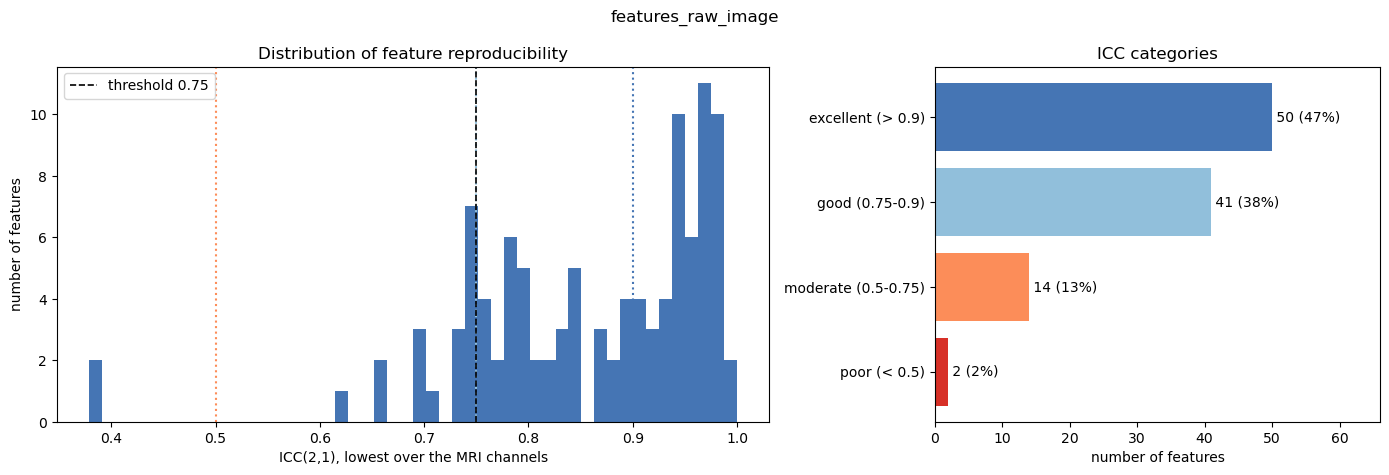

In [5]:
display(results["figures"]["overview"])

Reproducibility per image type and feature class

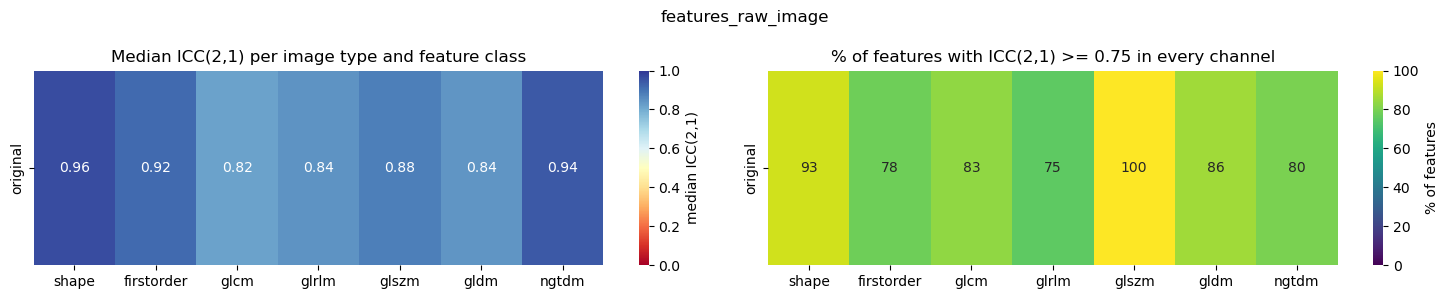

In [6]:
display(results["figures"]["class_and_image_type"])

## Perturbation that affects the most, and  channels / classes that are least reproducible

Left: ICC(2,1) between the baseline and each single perturbation. Right: ICC(2,1) over all conditions,
per feature class and MRI channel.

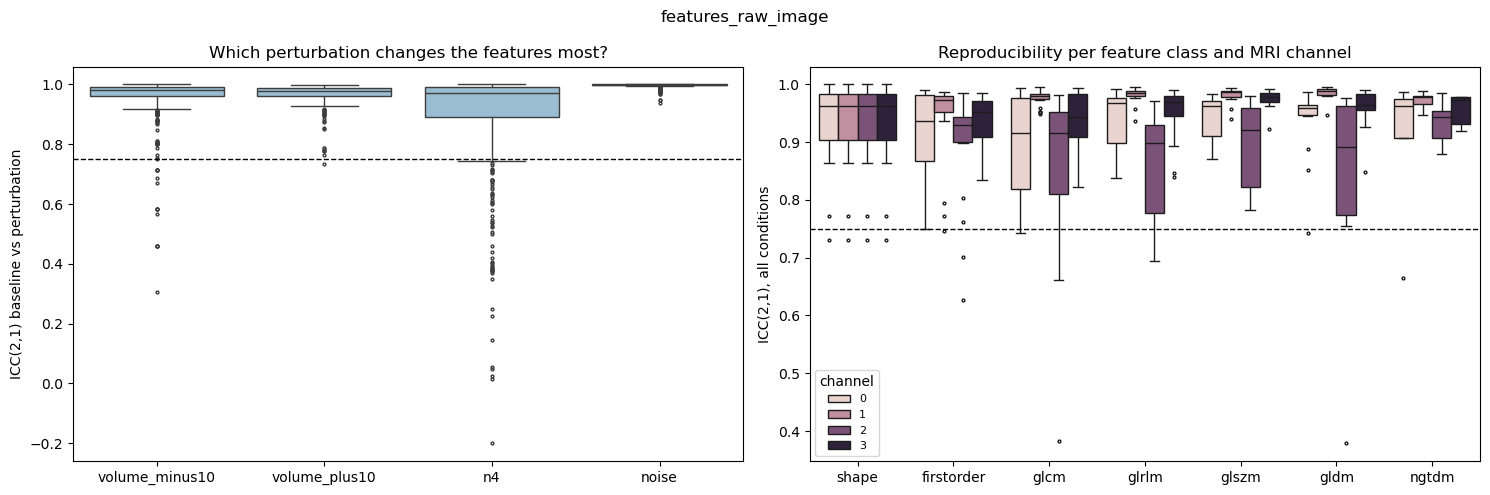

In [7]:
display(results["figures"]["perturbations_and_channels"])

Least reproducible features (with 95 % confidence interval)

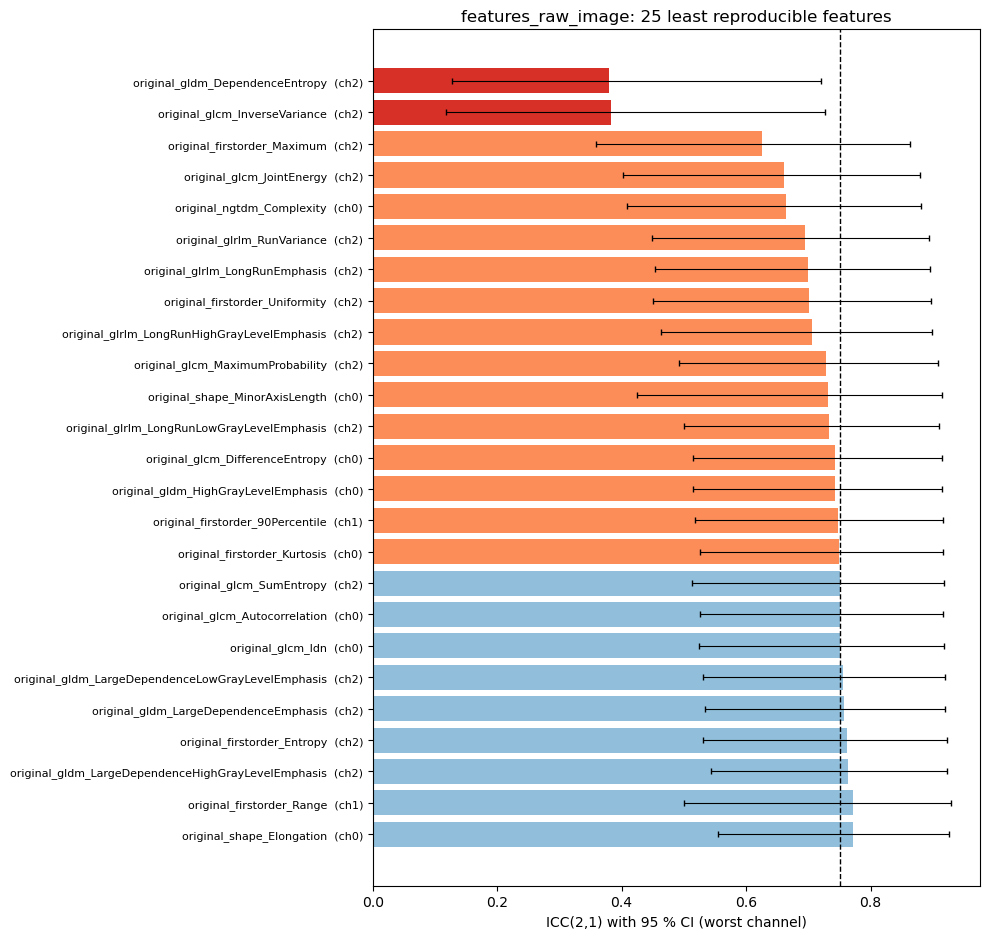

In [8]:
display(results["figures"]["least_reproducible"])

In [9]:
per_feature = results["per_feature"]
print(int(per_feature["reproducible"].sum()), "of", len(per_feature), "features are reproducible")
display(per_feature.round(3).head(20))                       # least reproducible first
display(results["per_channel"].round(3).head(10))           # all ICC forms per feature and channel

91 of 107 features are reproducible


,feature,image_type,feature_class,feature_name,icc21_min,icc21_median,icc21_ci_low_min,category,reproducible
0,original_gldm_DependenceEntropy,original,gldm,DependenceEntropy,0.379,0.962,0.127,poor (< 0.5),False
1,original_glcm_InverseVariance,original,glcm,InverseVariance,0.382,0.933,0.118,poor (< 0.5),False
2,original_firstorder_Maximum,original,firstorder,Maximum,0.626,0.872,0.358,moderate (0.5-0.75),False
3,original_glcm_JointEnergy,original,glcm,JointEnergy,0.661,0.913,0.403,moderate (0.5-0.75),False
4,original_ngtdm_Complexity,original,ngtdm,Complexity,0.664,0.899,0.408,moderate (0.5-0.75),False
5,original_glrlm_RunVariance,original,glrlm,RunVariance,0.695,0.974,0.449,moderate (0.5-0.75),False
6,original_glrlm_LongRunEmphasis,original,glrlm,LongRunEmphasis,0.699,0.969,0.454,moderate (0.5-0.75),False
7,original_firstorder_Uniformity,original,firstorder,Uniformity,0.701,0.879,0.450,moderate (0.5-0.75),False
8,original_glrlm_LongRunHighGrayLevelEmphasis,original,glrlm,LongRunHighGrayLevelEmphasis,0.706,0.967,0.463,moderate (0.5-0.75),False
9,original_glcm_MaximumProbability,original,glcm,MaximumProbability,0.729,0.933,0.493,moderate (0.5-0.75),False


,feature,channel,image_type,feature_class,feature_name,"ICC(1,1)","ICC(2,1)","ICC(3,1)","ICC(1,k)","ICC(2,k)","ICC(3,k)","ICC(2,1) CI low","ICC(2,1) CI high","ICC(2,1) vs volume_minus10","ICC(2,1) vs volume_plus10","ICC(2,1) vs n4","ICC(2,1) vs noise"
0,original_shape_Elongation,0,original,shape,Elongation,0.773,0.772,0.760,0.945,0.944,0.941,0.555,0.926,0.583,0.977,1.0,1.0
1,original_shape_Flatness,0,original,shape,Flatness,0.965,0.965,0.967,0.993,0.993,0.993,0.916,0.990,0.926,0.997,1.0,1.0
2,original_shape_LeastAxisLength,0,original,shape,LeastAxisLength,0.986,0.986,0.987,0.997,0.997,0.997,0.965,0.996,0.976,0.994,1.0,1.0
3,original_shape_MajorAxisLength,0,original,shape,MajorAxisLength,0.895,0.895,0.932,0.977,0.977,0.986,0.739,0.970,0.800,0.988,1.0,1.0
4,original_shape_Maximum2DDiameterColumn,0,original,shape,Maximum2DDiameterColumn,0.862,0.864,0.951,0.969,0.970,0.990,0.586,0.963,0.714,0.999,1.0,1.0
5,original_shape_Maximum2DDiameterRow,0,original,shape,Maximum2DDiameterRow,0.945,0.946,0.975,0.989,0.989,0.995,0.825,0.986,0.878,0.999,1.0,1.0
6,original_shape_Maximum2DDiameterSlice,0,original,shape,Maximum2DDiameterSlice,1.000,1.000,1.000,1.000,1.000,1.000,0.999,1.000,1.000,1.000,1.0,1.0
7,original_shape_Maximum3DDiameter,0,original,shape,Maximum3DDiameter,0.925,0.925,0.957,0.984,0.984,0.991,0.793,0.979,0.805,1.000,1.0,1.0
8,original_shape_MeshVolume,0,original,shape,MeshVolume,0.980,0.980,0.995,0.996,0.996,0.999,0.902,0.995,0.978,0.981,1.0,1.0
9,original_shape_MinorAxisLength,0,original,shape,MinorAxisLength,0.724,0.731,0.850,0.929,0.932,0.966,0.425,0.915,0.460,0.957,1.0,1.0


In [10]:
all_results = {}
# display chart
for csv_path in sorted(FEATURE_DIR.glob("features_*.csv")):
    all_results[csv_path.stem] = run_icc_analysis(csv_path, REPRO_DIR, OUTPUT_DIR, threshold=THRESHOLD)
    


features_binary_patterns: 279 features (0 without perturbed data) | 240 reproducible (ICC(2,1) >= 0.75 in every channel) | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/icc/features_binary_patterns
features_exponential_filter: 93 features (0 without perturbed data) | 78 reproducible (ICC(2,1) >= 0.75 in every channel) | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/icc/features_exponential_filter
features_gabor_filter: 372 features (0 without perturbed data) | 353 reproducible (ICC(2,1) >= 0.75 in every channel) | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/icc/features_gabor_filter
features_gradient_filter: 93 features (0 without perturbed data) | 75 reproducible (ICC(2,1) >= 0.75 in every channel) | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/icc/features_gradient_filter
features_laws_filter: 558 features (0 without perturbed data) | 524 reproducible (ICC(2,1) >= 0.75 in every 

,Feature CSV,Total Features,ICC Available,Reproducible,Not Reproducible,Missing ICC,Reproducibility (%)
0,features_binary_patterns,279,277,240,37,2,86.02
1,features_exponential_filter,93,93,78,15,0,83.87
2,features_gabor_filter,372,372,353,19,0,94.89
3,features_gradient_filter,93,93,75,18,0,80.65
4,features_laws_filter,558,558,524,34,0,93.91
5,features_log_filter,465,465,444,21,0,95.48
6,features_logarithmic_filter,93,93,71,22,0,76.34
7,features_raw_image,107,107,91,16,0,85.05
8,features_square_filter,93,93,81,12,0,87.10
9,features_square_root_filter,93,93,73,20,0,78.49


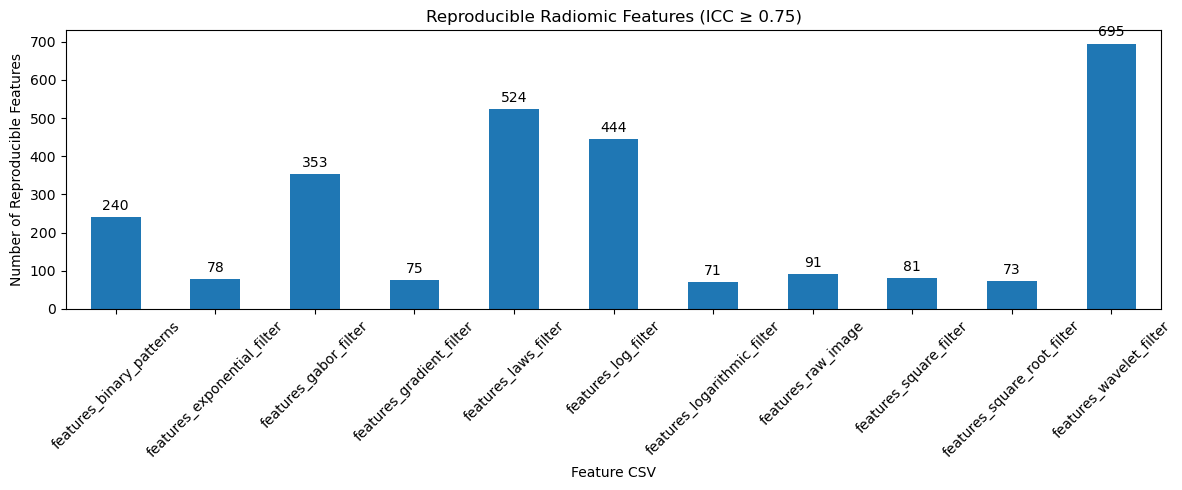

In [11]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

THRESHOLD = 0.75

summary = []

for name, result in all_results.items():
    missing = len(result["missing_features"])

    if "per_feature" not in result:
        summary.append({
            "Feature CSV": name,
            "Total Features": missing,
            "ICC Available": 0,
            "Reproducible": 0,
            "Not Reproducible": 0,
            "Missing ICC": missing,
            "Reproducibility (%)": 0.0
        })
        continue

    df = result["per_feature"]

    total = len(df) + missing
    available = df["icc21_min"].notna().sum()
    reproducible = (df["icc21_min"] >= THRESHOLD).sum()

    summary.append({
        "Feature CSV": name,
        "Total Features": total,
        "ICC Available": available,
        "Reproducible": reproducible,
        "Not Reproducible": available - reproducible,
        "Missing ICC": total - available,
        "Reproducibility (%)": round(
            100 * reproducible / total, 2
        ) if total else 0
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

# Bar chart
ax = summary_df.plot(
    x="Feature CSV",
    y="Reproducible",
    kind="bar",
    figsize=(12, 5),
    legend=False,
    rot=45
)

ax.set_title(f"Reproducible Radiomic Features (ICC ≥ {THRESHOLD})")
ax.set_xlabel("Feature CSV")
ax.set_ylabel("Number of Reproducible Features")
ax.bar_label(ax.containers[0], padding=3)

plt.tight_layout()
plt.show()


,Total_Features,Reproducible,ICC_Available,Not_Reproducible,Missing_ICC,Reproducibility_Percent
feature_class,,,,,,
firstorder,576,538,574,36,2,93.73
shape,14,13,14,1,0,92.86
glcm,768,690,768,78,0,89.84
glrlm,512,456,512,56,0,89.06
glszm,512,458,512,54,0,89.45
gldm,448,418,448,30,0,93.30
ngtdm,160,152,160,8,0,95.00


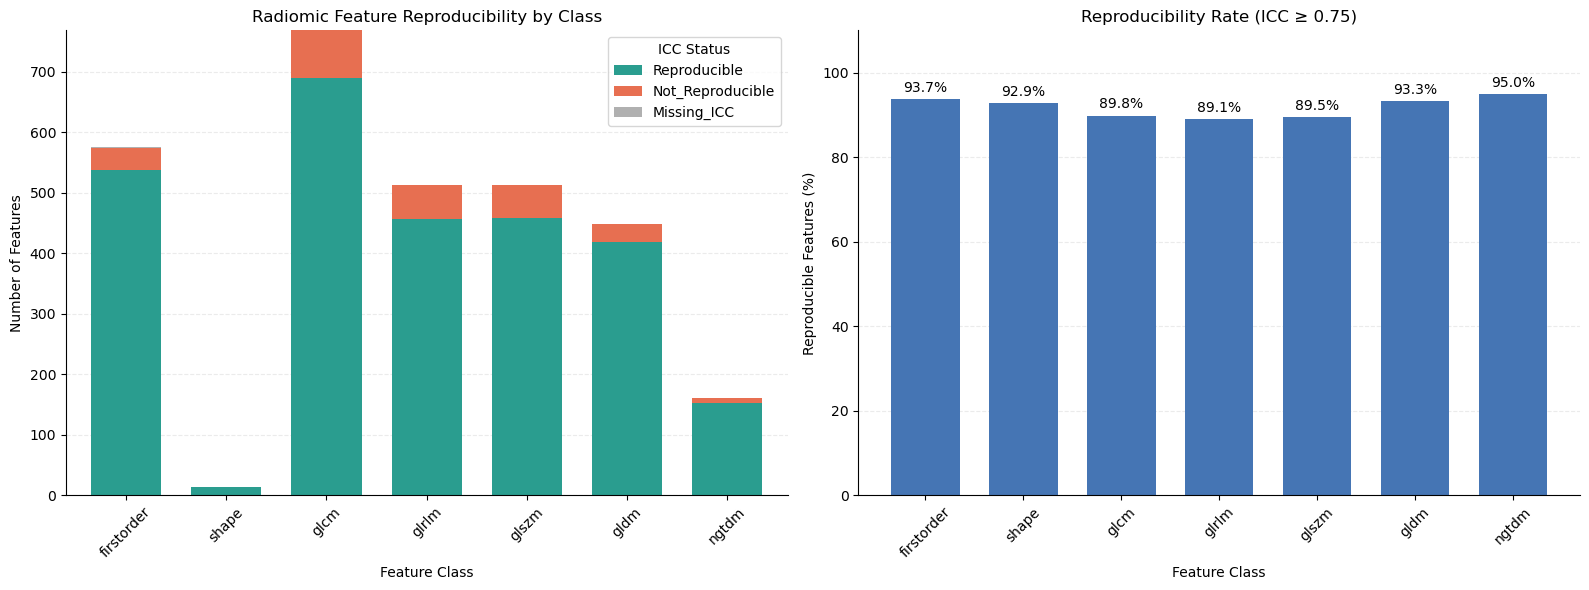

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

THRESHOLD = 0.75

CLASS_ORDER = [
    "firstorder", "shape", "glcm",
    "glrlm", "glszm", "gldm", "ngtdm"
]

# Collect feature-wise ICC results
records = []

for csv_name, result in all_results.items():

    if "per_feature" not in result:
        continue

    df = result["per_feature"].copy()
    df["source_csv"] = csv_name
    df["reproducible"] = df["icc21_min"] >= THRESHOLD

    records.append(df)

combined = pd.concat(records, ignore_index=True)

# Group by radiomic feature class
summary = (
    combined.groupby("feature_class")
    .agg(
        Total_Features=("feature", "count"),
        Reproducible=("reproducible", "sum"),
        ICC_Available=("icc21_min", "count")
    )
    .reset_index()
)

summary["Not_Reproducible"] = (
    summary["ICC_Available"] - summary["Reproducible"]
)

summary["Missing_ICC"] = (
    summary["Total_Features"] - summary["ICC_Available"]
)

summary["Reproducibility_Percent"] = (
    100 * summary["Reproducible"]
    / summary["ICC_Available"].replace(0, np.nan)
)

summary = summary.set_index("feature_class")
summary = summary.reindex(
    [c for c in CLASS_ORDER if c in summary.index]
)

display(summary.round(2))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Feature counts
summary[
    ["Reproducible", "Not_Reproducible", "Missing_ICC"]
].plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    color=["#2a9d8f", "#e76f51", "#b0b0b0"],
    width=0.7
)

axes[0].set_title("Radiomic Feature Reproducibility by Class")
axes[0].set_xlabel("Feature Class")
axes[0].set_ylabel("Number of Features")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="ICC Status")

# Chart 2: Reproducibility percentage
bars = axes[1].bar(
    summary.index,
    summary["Reproducibility_Percent"],
    color="#4575b4",
    width=0.7
)

axes[1].bar_label(bars, fmt="%.1f%%", padding=3)
axes[1].set_title(f"Reproducibility Rate (ICC ≥ {THRESHOLD})")
axes[1].set_xlabel("Feature Class")
axes[1].set_ylabel("Reproducible Features (%)")
axes[1].set_ylim(0, 110)
axes[1].tick_params(axis="x", rotation=45)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()